[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/7_eigenvectors_of_G_per_scale.ipynb)

# Leading eigenvectors of G(x) at each noise level

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Split G(x) into its contributions from each noise level, $M_t(x)$, and plot the leading eigenvectors of $M_t(x)$ against the noise level, for the Inception models of V1 and V4 and the example images of the landing page (task 1 of the note *Scale-resolved decomposition of G(x)*).

* **Requirements**: TinyImageNet and the trained checkpoints (downloaded below), a GPU, and a version of `multigeom` that has `compute_g_per_scale` (newer than 0.1.0.dev4: until it is released, install the package from a clone, see the README).

* **Time**: about 6 min on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub: on Google Colab always (with `diffusers`), elsewhere only if the installed one lacks its functions.

time: <1 sec

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom.config": {"load_config": []},
        "multigeom.datasets": {"download_tinyimagenet": [], "load_examples": []},
        "multigeom.diffusion.model": {"build_scheduler": []},
        "multigeom.encoders.receptive_field": {"compute_rf_outline": []},
        "multigeom.pipeline.metric_field": {"load_models": []},
        "multigeom.pipeline.per_scale": {"compute_per_scale": []},
        "multigeom.plotting": {"plot_per_scale": []},
        "multigeom.utils": {
            "get_device": [],
            "load_intermediate": [],
            "save_intermediate": [],
        },
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

CPU times: user 4.15 s, sys: 191 ms, total: 4.34 s
Wall time: 1.77 s


### 1.2. Imports and parameters

Work from the repository root, import the packages and the helpers of the per-scale analyses (`multigeom.plotting`, `multigeom.analysis` and others in the package), and set the parameters: the encoder, the example images, the number of samples per noise level, and where the figures go.

<details><summary>Details</summary>

* `load_examples` loads the example images, `compute_per_scale` computes $M_t(x)$ at each noise level for each of them, and `plot_per_scale` draws the figure of one image (the sign of each eigenvector chosen by `align_signs`) and returns the data it shows.

</details>

time: 1 sec

In [2]:
%%time

import copy
import os
from pathlib import Path

import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet, load_examples
from multigeom.diffusion.model import build_scheduler
from multigeom.encoders.receptive_field import compute_rf_outline
from multigeom.pipeline.metric_field import load_models
from multigeom.pipeline.per_scale import compute_per_scale
from multigeom.plotting import plot_per_scale
from multigeom.utils import get_device, load_intermediate, save_intermediate

# the parameters of this notebook
PARAMS = {
    # the encoder, fitted to each of the two areas
    "encoder": "inception",
    "areas": ["V1", "V4"],
    # the example images of the landing page (https://multigeom.github.io): the frog of
    # paper Fig. 3D (the first TinyImageNet training image of the class n01644900),
    # then test images, by their index among the TinyImageNet validation images in
    # sorted file order (the test images of notebook 4)
    "frog": "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG",
    "test_images": [0, 3, 9, 16, 27, 41, 58, 72, 95, 118, 150, 187],
    # Monte-Carlo samples per noise level (the paper uses 200 for G(x))
    "n_samples": 200,
    # leading eigenvectors kept and drawn at each noise level
    "n_eigvecs": 4,
    # where the figures are saved (one per image), their resolution in the file and
    # where the computed results are stored, so that a new run reloads them in seconds
    # instead of recomputing them (True: recompute and overwrite them)
    "intermediate_dir": "data/02_intermediate/7_eigenvectors_of_G_per_scale",
    "recompute": False,
    # on screen, and the images whose figures stay in the notebook (each is about 1 MB)
    "figure_dir": "assets/figures/task1",
    "file_dpi": 200,
    "screen_dpi": 100,
    "show": ["frog"],
}

# the diffusion and estimator configs (packaged with multigeom)
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials
device: cuda
CPU times: user 2.32 ms, sys: 17 μs, total: 2.34 ms
Wall time: 2.27 ms


## 2. Download trained encoders and diffusion models

The checkpoints (the fitted readouts and the diffusion models) are on Hugging Face. The InceptionV3 weights are downloaded by torchvision on first use.

time: <1 sec

In [3]:
%%time

# download the checkpoints into runs/ (files that are already there are kept; the
# archive/ folder of older checkpoints and the retina models, */lorenzi/, are skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns=["archive/*", "*/lorenzi/*"],
)

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 71.2 ms, sys: 10.1 ms, total: 81.3 ms
Wall time: 248 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the example images (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet: the frog and the test images (nothing if already there)
download_tinyimagenet()

# the stored results of this notebook, from the dataset
# steevelaquitaine/multigeom-results, if they are published there; otherwise the
# notebook computes them (no download with PARAMS["recompute"])
from huggingface_hub import snapshot_download as download_results

if not PARAMS.get("recompute", False):  # recomputed anyway otherwise
    try:
        download_results(
            repo_id="steevelaquitaine/multigeom-results",
            repo_type="dataset",
            local_dir="data/02_intermediate",
            allow_patterns=["7_eigenvectors_of_G_per_scale/*"],
        )
    except Exception as error:  # not published yet, or offline
        print("stored results not downloaded:", type(error).__name__)

Fetching 0 files: 0it [00:00, ?it/s]

CPU times: user 6.62 ms, sys: 86 μs, total: 6.71 ms
Wall time: 109 ms


## 4. Compute $M_t(x)$ at each noise level

G(x) adds up, over the noise levels t, the information that the responses carry about the image: $G(x) = \int M_t(x)\, d\log t$. We estimate the integrand $M_t(x)$ at each of the 24 noise levels of the paper's grid, for each example image and for the models of V1 and V4, and keep its leading 4 eigenvectors and eigenvalues. The results are stored in `data/02_intermediate/7_eigenvectors_of_G_per_scale/` and reloaded on later runs (set `"recompute": True` to recompute them).

<details><summary>Details</summary>

* **Definition.** With $x_t = x + \sqrt{t}\,\epsilon$ the image plus Gaussian noise of variance $t$, and $r, r'$ two responses drawn independently given $x_t$,
  $$M_t(x) = \tfrac12\, \mathbb{E}\left[\tfrac1t \left(\hat x(x_t, r) - \hat x(x_t, r')\right)\left(\hat x(x_t, r) - \hat x(x_t, r')\right)^\top\right],$$
  where $\hat x(x_t, r) = \mathbb{E}[x \mid x_t, r]$ is the denoiser of the conditional diffusion model. It is the integrand of G(x), without the integral over $t$.
* **Noise levels.** Those of the paper's G(x): the DDPM steps 40, 80, ..., 960, that is $\tau = \log t$ from −3.9 to 9.3 (natural log, $t$ in the units of the image, whose pixels are in [−1, 1]). The package calls the noise variance τ, so the `log_tau` that `compute_g_per_scale` returns is $\tau = \log t$ here.
* **Algorithm.** Algorithm 1 of the paper, one noise level at a time: the 200 rows of D drawn at that level, without the trapezoid weight, then one SVD per level. As for G(x), the responses are drawn given the denoised image, $r \sim p(r \mid \hat x(x_t))$.
* **The same samples as G(x).** With the same seed, `compute_g_per_scale` draws the samples of `compute_g`, so the $M_t(x)$ weighted by the trapezoid rule add up to G(x) (checked by the tests of the package). The test images have the seeds of the pipeline (notebook 4), the frog that of notebook 3.
* **Noise of the estimate.** Each $M_t(x)$ rests on 200 samples, 24 times fewer than G(x). At fine noise levels ($\tau < 2$) its leading eigenvalues are nearly equal, and its leading eigenvectors change with the seed: for test image 0, two seeds agree with $|\cos|$ between 0.11 and 0.97 on the leading eigenvector, against at least 0.94 at $\tau > 2$. With 2,000 samples per level (`"n_samples": 2000`, about 10 times longer), they agreed with $|\cos| \ge 0.93$ at the fine levels we tested.

</details>

time: 5 min

In [5]:
%%time

# 1. estimator settings: those of the paper, with n_samples Monte-Carlo samples per
# noise level, and the n_eigvecs leading eigenpairs kept at each level
cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = PARAMS["n_samples"]
cfg.top_k = PARAMS["n_eigvecs"]

# 2. the example images, with their seeds
examples = load_examples(PARAMS, int(cfg.seed))

# 3. the noise schedule of the diffusion models (the ᾱ of each DDPM step)
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

# 4. for each area: load its encoder and diffusion model, then compute M_t(x) of every
# image; results[area][name] holds tau = log t, the eigenvalues and the eigenvectors,
# and outlines[area] the region of the image its neurons cover
results_file = Path(PARAMS["intermediate_dir"]) / "results.pt"
if results_file.exists() and not PARAMS["recompute"]:
    results, outlines = load_intermediate(results_file)
else:
    results, outlines = {}, {}
    for area in PARAMS["areas"]:
        encoder, unet, _ = load_models(
            PARAMS["encoder"], area, Path("runs"), None, diff_cfg, True, device
        )
        results[area] = compute_per_scale(
            examples, encoder, unet, alphas_cumprod, cfg, device
        )
        outlines[area] = compute_rf_outline(encoder.state_dict())
        print(area, "done:", len(results[area]), "images")
    save_intermediate((results, outlines), results_file)

V1 done: 13 images


V4 done: 13 images
CPU times: user 4min 9s, sys: 1min 12s, total: 5min 21s
Wall time: 5min 19s


## 5. Plot the leading eigenvectors at each noise level

One figure per image, saved to `assets/figures/task1/eigenvectors_per_scale_<image>.png`; to keep the notebook small, it shows only those of the images in `PARAMS["show"]` (the frog). Each figure has the image (A), the leading 4 eigenvectors of $M_t(x)$ at each noise level for V1 (B) and V4 (C), from the finest noise level (left) to the coarsest (right), and their eigenvalues, each area over its largest leading eigenvalue (D).

<details><summary>Details</summary>

* Each eigenvector is drawn like those of Fig. 3E: red positive, blue negative, scaled to its own 99th percentile of |v|.
* The sign of an eigenvector is arbitrary. For display, each takes the sign that agrees with the same eigenvector at the next coarser level, and those of the coarsest level have a positive sum.
* The coloured outlines mark the region of the image that the neurons of each area cover on the image and on the tiles of their area (V1 blue, V4 orange; the contour at half the largest of their Gaussian readouts, as in Fig. 3D): the eigenvectors matter there, where the areas see the image.
* In D, the leading eigenvalue of each area is thick and the next three are thin, on a linear axis; the columns are those of B and C. All the eigenvalues of an area are divided by the largest of its leading ones, so the two areas compare by where along $\tau$ they sit, not by their size.

</details>

time: 16 secs

13 figures saved in assets/figures/task1
CPU times: user 24.8 s, sys: 942 ms, total: 25.7 s
Wall time: 23.6 s


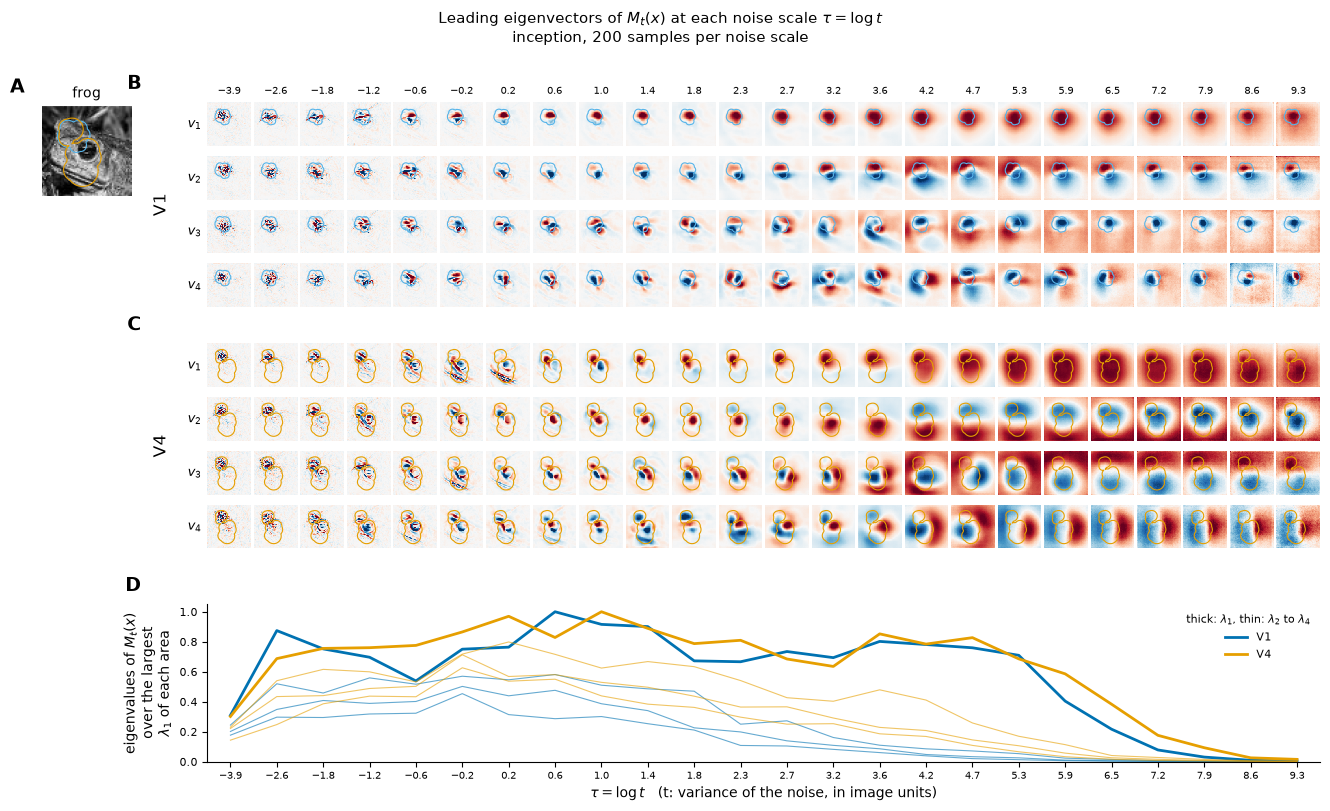

In [6]:
%%time

# 1. the folder of the figures, and the title of every figure
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
suptitle = (
    r"Leading eigenvectors of $M_t(x)$ at each noise scale $\tau = \log t$"
    f"\n{PARAMS['encoder']}, {PARAMS['n_samples']} samples per noise scale"
)

# 2. one figure per image: draw it, keep the data it shows, and save it; only the
# figures of the images in PARAMS["show"] stay in the notebook
plotted = {}
for name, (image, _) in examples.items():
    records = {area: results[area][name] for area in PARAMS["areas"]}
    fig, plotted[name] = plot_per_scale(
        image, records, PARAMS, name, suptitle, outlines
    )
    fig.savefig(
        figure_dir / f"eigenvectors_per_scale_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)

# 3. where the figures are
print(len(plotted), "figures saved in", figure_dir)

## 6. Conclusion

* **What we computed.** $M_t(x)$, the integrand of G(x), at the 24 noise levels of the paper's grid ($\tau = \log t$ from −3.9 to 9.3), for the 13 example images of the landing page and the Inception models of V1 and V4, with 200 samples per level: about 5 min on one GPU. The figures are in `assets/figures/task1/`.
* **From the model to the image.** At coarse noise levels ($\tau \gtrsim 6$) the leading eigenvectors are smooth patterns over the receptive fields, and the same patterns come back in the figure of every example image: the noise hides the image, and what is left is the structure of the model. As the noise decreases, they shrink and follow the image (the eye of the frog).
* **Where the information lies.** In panel D, each area's eigenvalues over its largest leading one stay roughly level from $\tau \approx -2.6$ to 5 and fall towards zero at the coarsest levels, more slowly for V4 than for V1, consistent with the larger receptive fields of V4.
* **Caveat.** With 200 samples per noise level, the leading eigenvectors at fine levels ($\tau < 2$) change from one seed to the next (details of section 4); those at coarse levels do not. Raise `"n_samples"` before reading the fine levels in detail.
* **Next steps.** Task 2 of the note, the same decomposition for the stimulus statistics alone, $M^{\rm env}_t(x)$, drawn next to these figures, is notebook 8; then the spectra $\rho^{\rm env}(\tau)$ and $\rho(\tau)$ (tasks 3 and 4).